# Global Maternal Mortality, 2000–2023

Trends, inequalities and exploratory associations. Author: Dr. Aung Chit Moe, MBBS.

WHO/UN MMEIG already uses GDP, general fertility and skilled birth attendance. Regression results are conditional associations with modeled national outcomes. They do not independently establish causal effects or individual clinical risk.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root / 'src'))
from research_io import load_results
r, audit = load_results(root)
df = pd.read_csv(root / 'data/processed/maternal_mortality_analytical_master.csv')
display(pd.DataFrame([r['sample']]))
print('Analytical SHA-256:', r['data_sha256'])

,all_countries,all_rows,balanced_countries,balanced_rows,complete_rows,complete_countries
0,195,4680,177,4248,4406,186


Analytical SHA-256: 1dc945fec2030f3e21e5f47bd0ccfd31bc3dfbb036dcf9c070cc14213522e0e2


## Data quality and sample selection

The audit calculates its outcome. Missing raw files in a lightweight clone are reported as NOT_CACHED. Integrity checks do not establish absence of bias.

In [2]:
display(pd.DataFrame(audit['checks']))
display(pd.read_csv(root / 'reports/tables/sample_selection.csv'))
display(pd.DataFrame(r['excluded']))

,check,violations,status
0,Unique country-year keys,0,PASS
1,One complete 2000–2023 outcome grid per country,0,PASS
2,Finite positive MMR and ordered uncertainty li...,0,PASS
3,gdp_pcap_ppp: finite positive observed values,0,PASS
4,chex_gdp_pct: finite positive observed values,0,PASS
5,tfr: finite positive observed values,0,PASS
6,live_births: finite positive observed values,0,PASS
7,Finite nonnegative observed adolescent fertility,0,PASS
8,"Observed urban percentages in [0,100]",0,PASS
9,log_mmr_pt: consistent with natural logarithm,0,PASS


,year,group,n_countries,median_mmr,mean_mmr,log_gdp_pcap_ppp_median,log_gdp_pcap_ppp_missing_pct,chex_gdp_pct_median,chex_gdp_pct_missing_pct,tfr_median,tfr_missing_pct,ado_fert_rate_median,ado_fert_rate_missing_pct,urban_pct_median,urban_pct_missing_pct
0,2000,Included,177,67.640559,217.743581,9.210073,0.0,4.865499,0.000000,2.744,0.000000,48.544,0.000000,53.933215,0.000000
1,2000,Excluded,18,137.241021,409.928241,8.983939,50.0,4.666066,61.111111,4.068,5.555556,60.988,5.555556,59.089926,5.555556
2,2023,Included,177,42.106051,109.566507,9.743601,0.0,6.534596,0.000000,1.975,0.000000,31.887,0.000000,62.251832,0.000000
3,2023,Excluded,18,92.651683,186.021823,8.781199,50.0,4.654433,22.222222,2.707,5.555556,48.674,5.555556,65.473167,5.555556


,country_iso3,country_name,income_level_name
0,AFG,Afghanistan,Low income
1,COK,Cook Islands,Unclassified
2,CUB,Cuba,Upper middle income
3,DJI,Djibouti,Lower middle income
4,ERI,Eritrea,Low income
5,IRQ,Iraq,Upper middle income
6,MCO,Monaco,High income
7,MNE,Montenegro,Upper middle income
8,PRI,Puerto Rico (US),High income
9,PRK,"Korea, Dem. People's Rep.",Low income


## Descriptive trends

Country averages weight countries equally. The derived aggregate ratio uses summed country median death estimates and live births and can differ from the official global posterior estimate. Income classifications are fixed at acquisition.

,year,n_countries,median_mmr,mean_mmr,maternal_deaths,live_births,aggregate_mmr
0,2000,195,70.987927,235.483703,440079.240110,135308747.0,325.240792
10,2010,195,56.142035,185.885230,359736.187343,142998217.0,251.566904
15,2015,195,51.872347,155.752747,322169.241513,143933653.0,223.831769
23,2023,195,46.647772,116.623920,248742.940371,131840623.0,188.669421


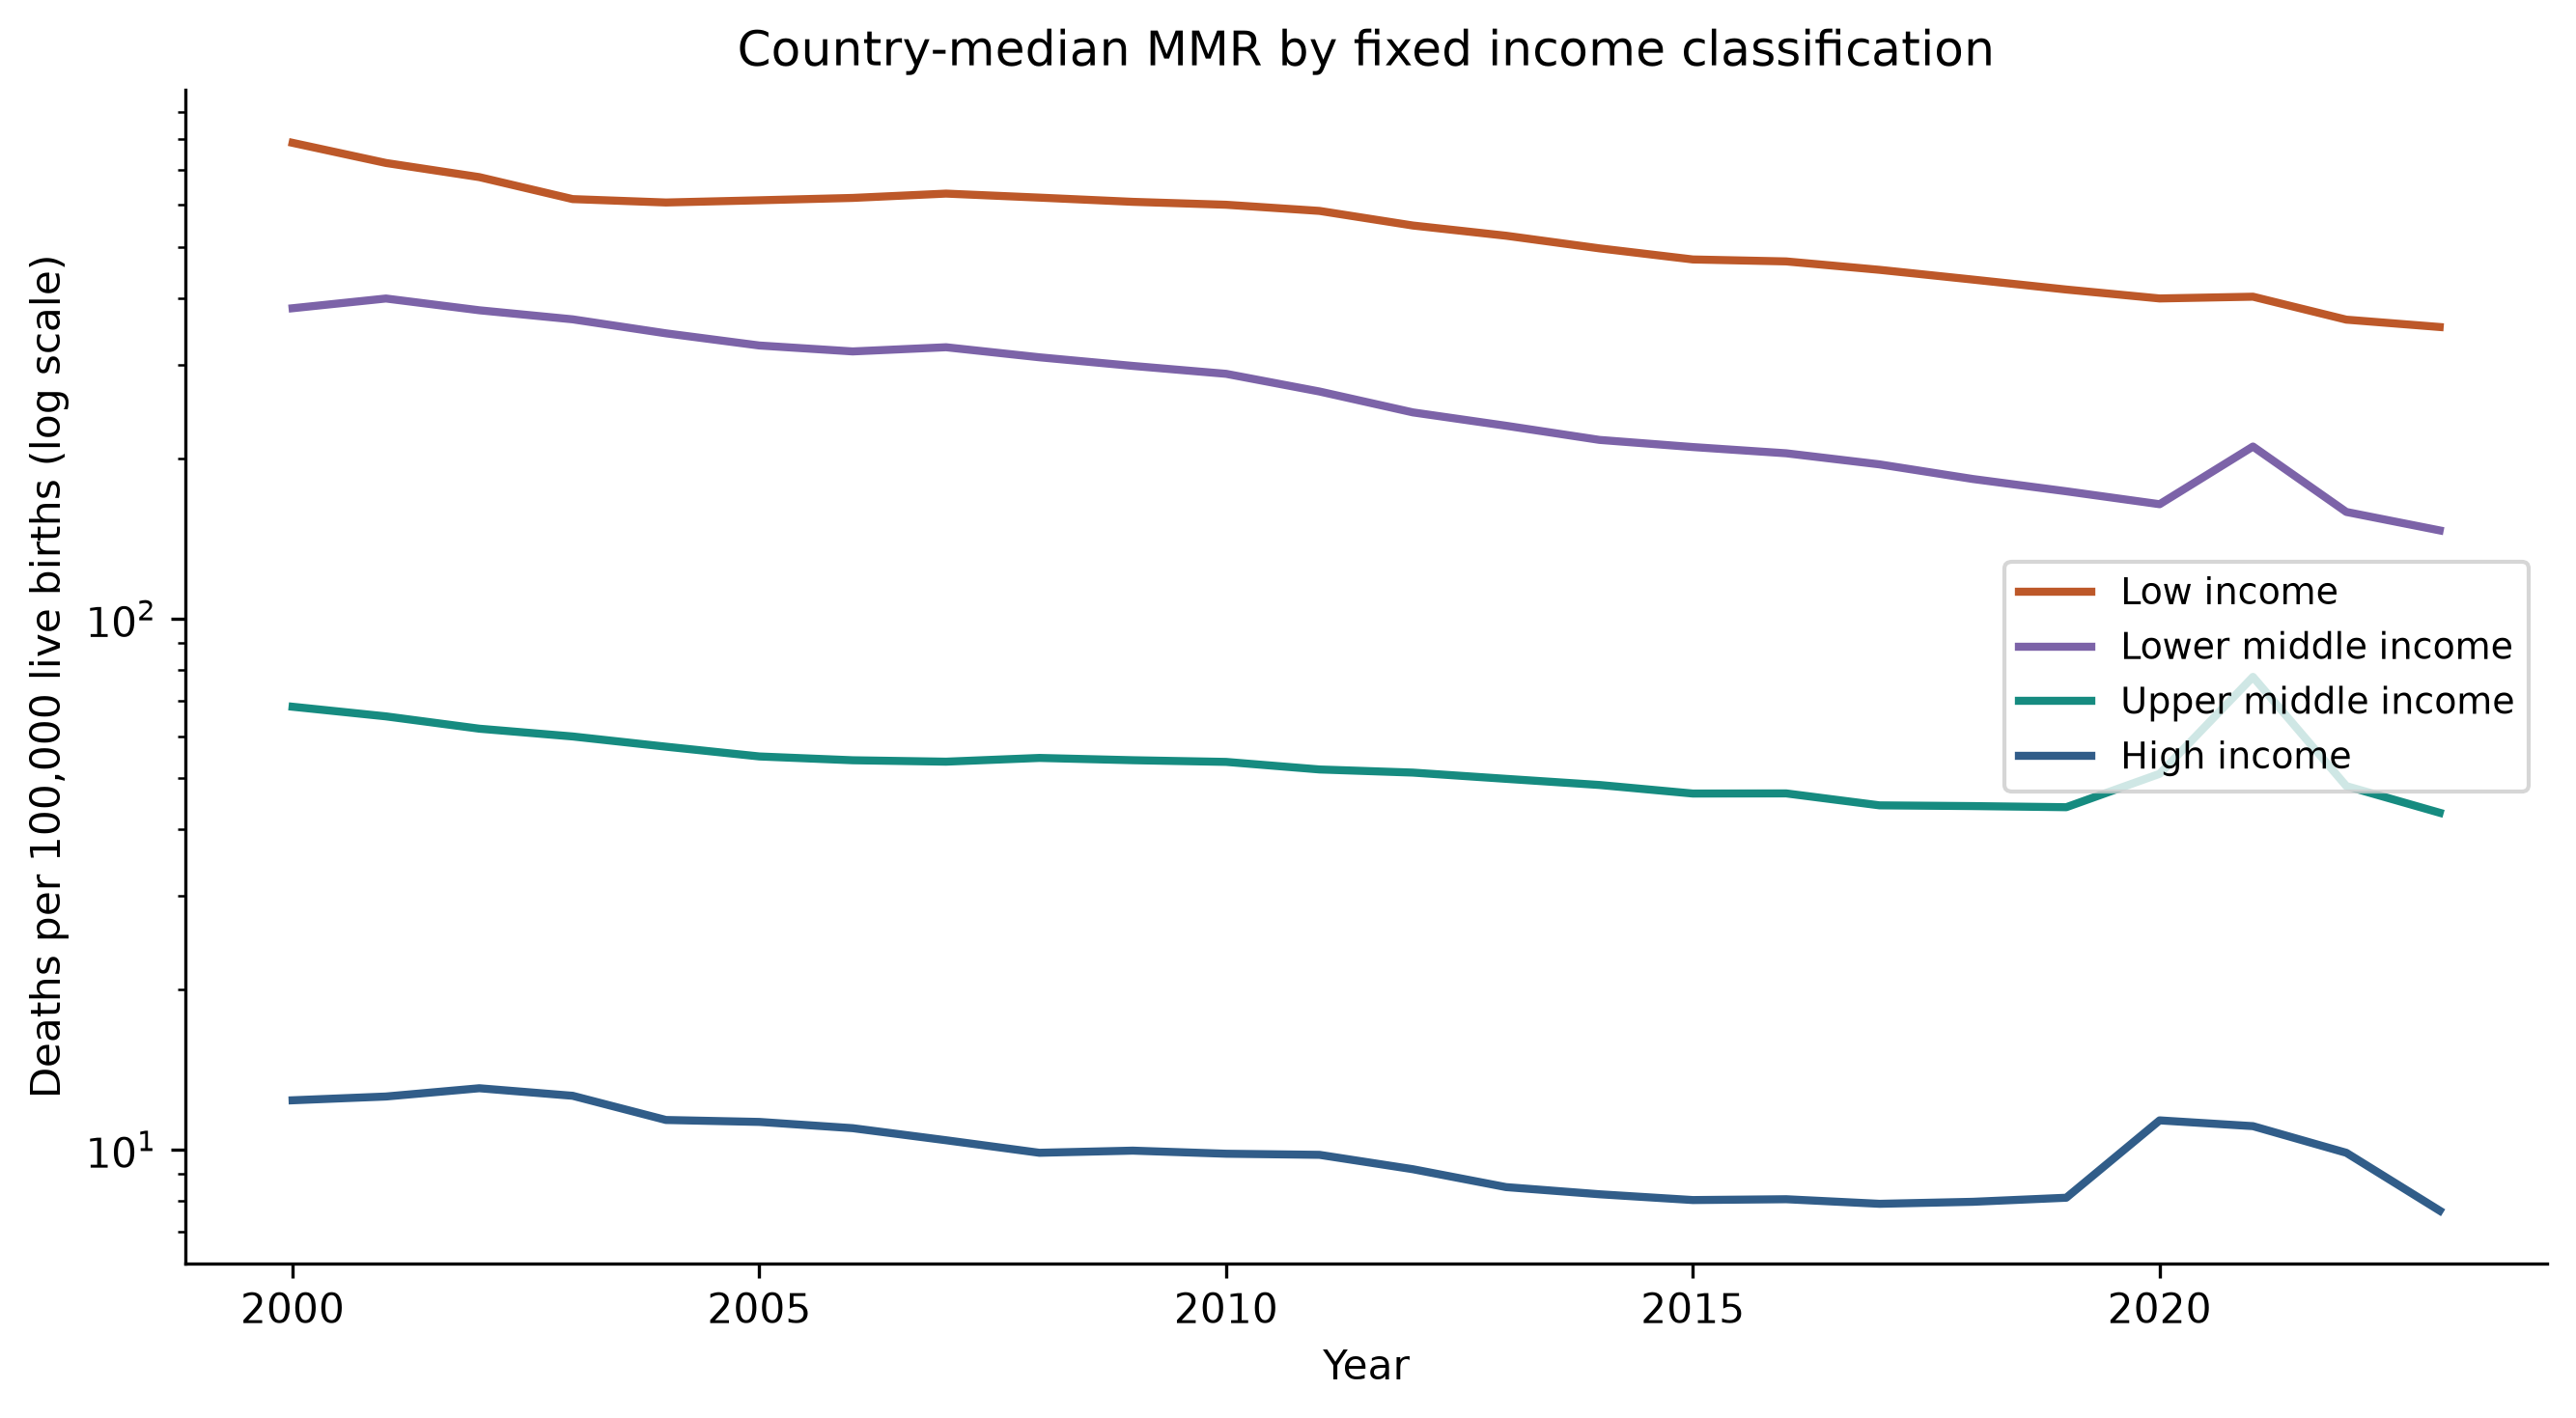

In [3]:
display(pd.DataFrame(r['global_trends']).query('year in [2000, 2010, 2015, 2023]'))
display(Image(filename=str(root / 'docs/images/fig1_mmr_trends_by_income.png')))

## Exploratory models

The panel models include explicit country and year dummy variables, with country-clustered t inference. This handles the unbalanced sample without incorrectly applying rectangular two-way demeaning. Income subsets and first differences are exploratory sensitivity analyses.

In [4]:
for key, model in r['models'].items():
    print(model['label'], 'countries:', model['n_countries'], 'rows:', model['n_obs'])
    display(pd.DataFrame(model['coefficients']))

Balanced panel countries: 177 rows: 4248


,term,label,coefficient,se,ci_low,ci_high,p_value
0,log_gdp_pcap_ppp,Log GDP per capita (constant PPP),-0.495949,0.076811,-0.647539,-0.344360,1.007311e-09
1,chex_gdp_pct,Current health expenditure (% GDP),0.010967,0.006729,-0.002313,0.024247,1.049340e-01
2,tfr,Total fertility (births/woman),0.130770,0.062404,0.007613,0.253927,3.755487e-02
3,ado_fert_rate,"Adolescent fertility (births/1,000)",-0.000711,0.002070,-0.004795,0.003374,7.317567e-01
4,urban_pct,Urban population (%),-0.004526,0.003673,-0.011775,0.002723,2.195277e-01


All complete country-years countries: 186 rows: 4406


,term,label,coefficient,se,ci_low,ci_high,p_value
0,log_gdp_pcap_ppp,Log GDP per capita (constant PPP),-0.493637,0.071970,-0.635624,-0.351649,1.008245e-10
1,chex_gdp_pct,Current health expenditure (% GDP),0.008754,0.006558,-0.004185,0.021693,1.835803e-01
2,tfr,Total fertility (births/woman),0.143230,0.058152,0.028503,0.257956,1.469160e-02
3,ado_fert_rate,"Adolescent fertility (births/1,000)",-0.000706,0.001958,-0.004568,0.003157,7.189694e-01
4,urban_pct,Urban population (%),-0.003850,0.003414,-0.010585,0.002885,2.609042e-01


Balanced panel, 2000–2019 countries: 177 rows: 3540


...

,term,label,coefficient,se,ci_low,ci_high,p_value
0,log_gdp_pcap_ppp,Log GDP per capita (constant PPP),-0.532181,0.089705,-0.709252,-0.355109,1.612835e-08
1,chex_gdp_pct,Current health expenditure (% GDP),-0.030234,0.027928,-0.085363,0.024895,2.805266e-01
2,tfr,Total fertility (births/woman),0.261564,0.051113,0.160671,0.362458,8.261874e-07
3,ado_fert_rate,"Adolescent fertility (births/1,000)",0.009046,0.001734,0.005623,0.012469,5.223535e-07
4,urban_pct,Urban population (%),-0.002238,0.003938,-0.010012,0.005536,5.706246e-01


2010 cross-section countries: 177 rows: 177


,term,label,coefficient,se,ci_low,ci_high,p_value
0,log_gdp_pcap_ppp,Log GDP per capita (constant PPP),-0.646679,0.104228,-0.852417,-0.440940,4.007490e-09
1,chex_gdp_pct,Current health expenditure (% GDP),-0.045520,0.022779,-0.090484,-0.000556,4.726657e-02
2,tfr,Total fertility (births/woman),0.150271,0.068030,0.015984,0.284558,2.851214e-02
3,ado_fert_rate,"Adolescent fertility (births/1,000)",0.012558,0.002059,0.008493,0.016623,6.930115e-09
4,urban_pct,Urban population (%),-0.001810,0.003918,-0.009543,0.005923,6.446823e-01


2023 cross-section countries: 177 rows: 177


,term,label,coefficient,se,ci_low,ci_high,p_value
0,log_gdp_pcap_ppp,Log GDP per capita (constant PPP),-0.809834,0.106737,-1.020526,-0.599142,2.008532e-12
1,chex_gdp_pct,Current health expenditure (% GDP),-0.037942,0.027506,-0.092236,0.016352,1.695673e-01
2,tfr,Total fertility (births/woman),-0.001229,0.102830,-0.204208,0.201750,9.904782e-01
3,ado_fert_rate,"Adolescent fertility (births/1,000)",0.014058,0.003081,0.007977,0.020140,9.579960e-06
4,urban_pct,Urban population (%),0.001011,0.003884,-0.006656,0.008678,7.949461e-01


## Diagnostics and sensitivity

Lower/upper outcome limits are marginal quantiles rather than joint posterior draws. Replacing outcomes with these limits does not propagate full estimation uncertainty. VIF and influence checks diagnose instability without resolving confounding.

,term,label,vif
0,log_gdp_pcap_ppp,Log GDP per capita (constant PPP),1.047466
1,chex_gdp_pct,Current health expenditure (% GDP),1.036350
2,tfr,Total fertility (births/woman),1.841069
3,ado_fert_rate,"Adolescent fertility (births/1,000)",1.716295
4,urban_pct,Urban population (%),1.115499


,residual_lag1_correlation,leave_one_out_gdp_min,leave_one_out_gdp_max
0,0.742657,-0.517649,-0.469656


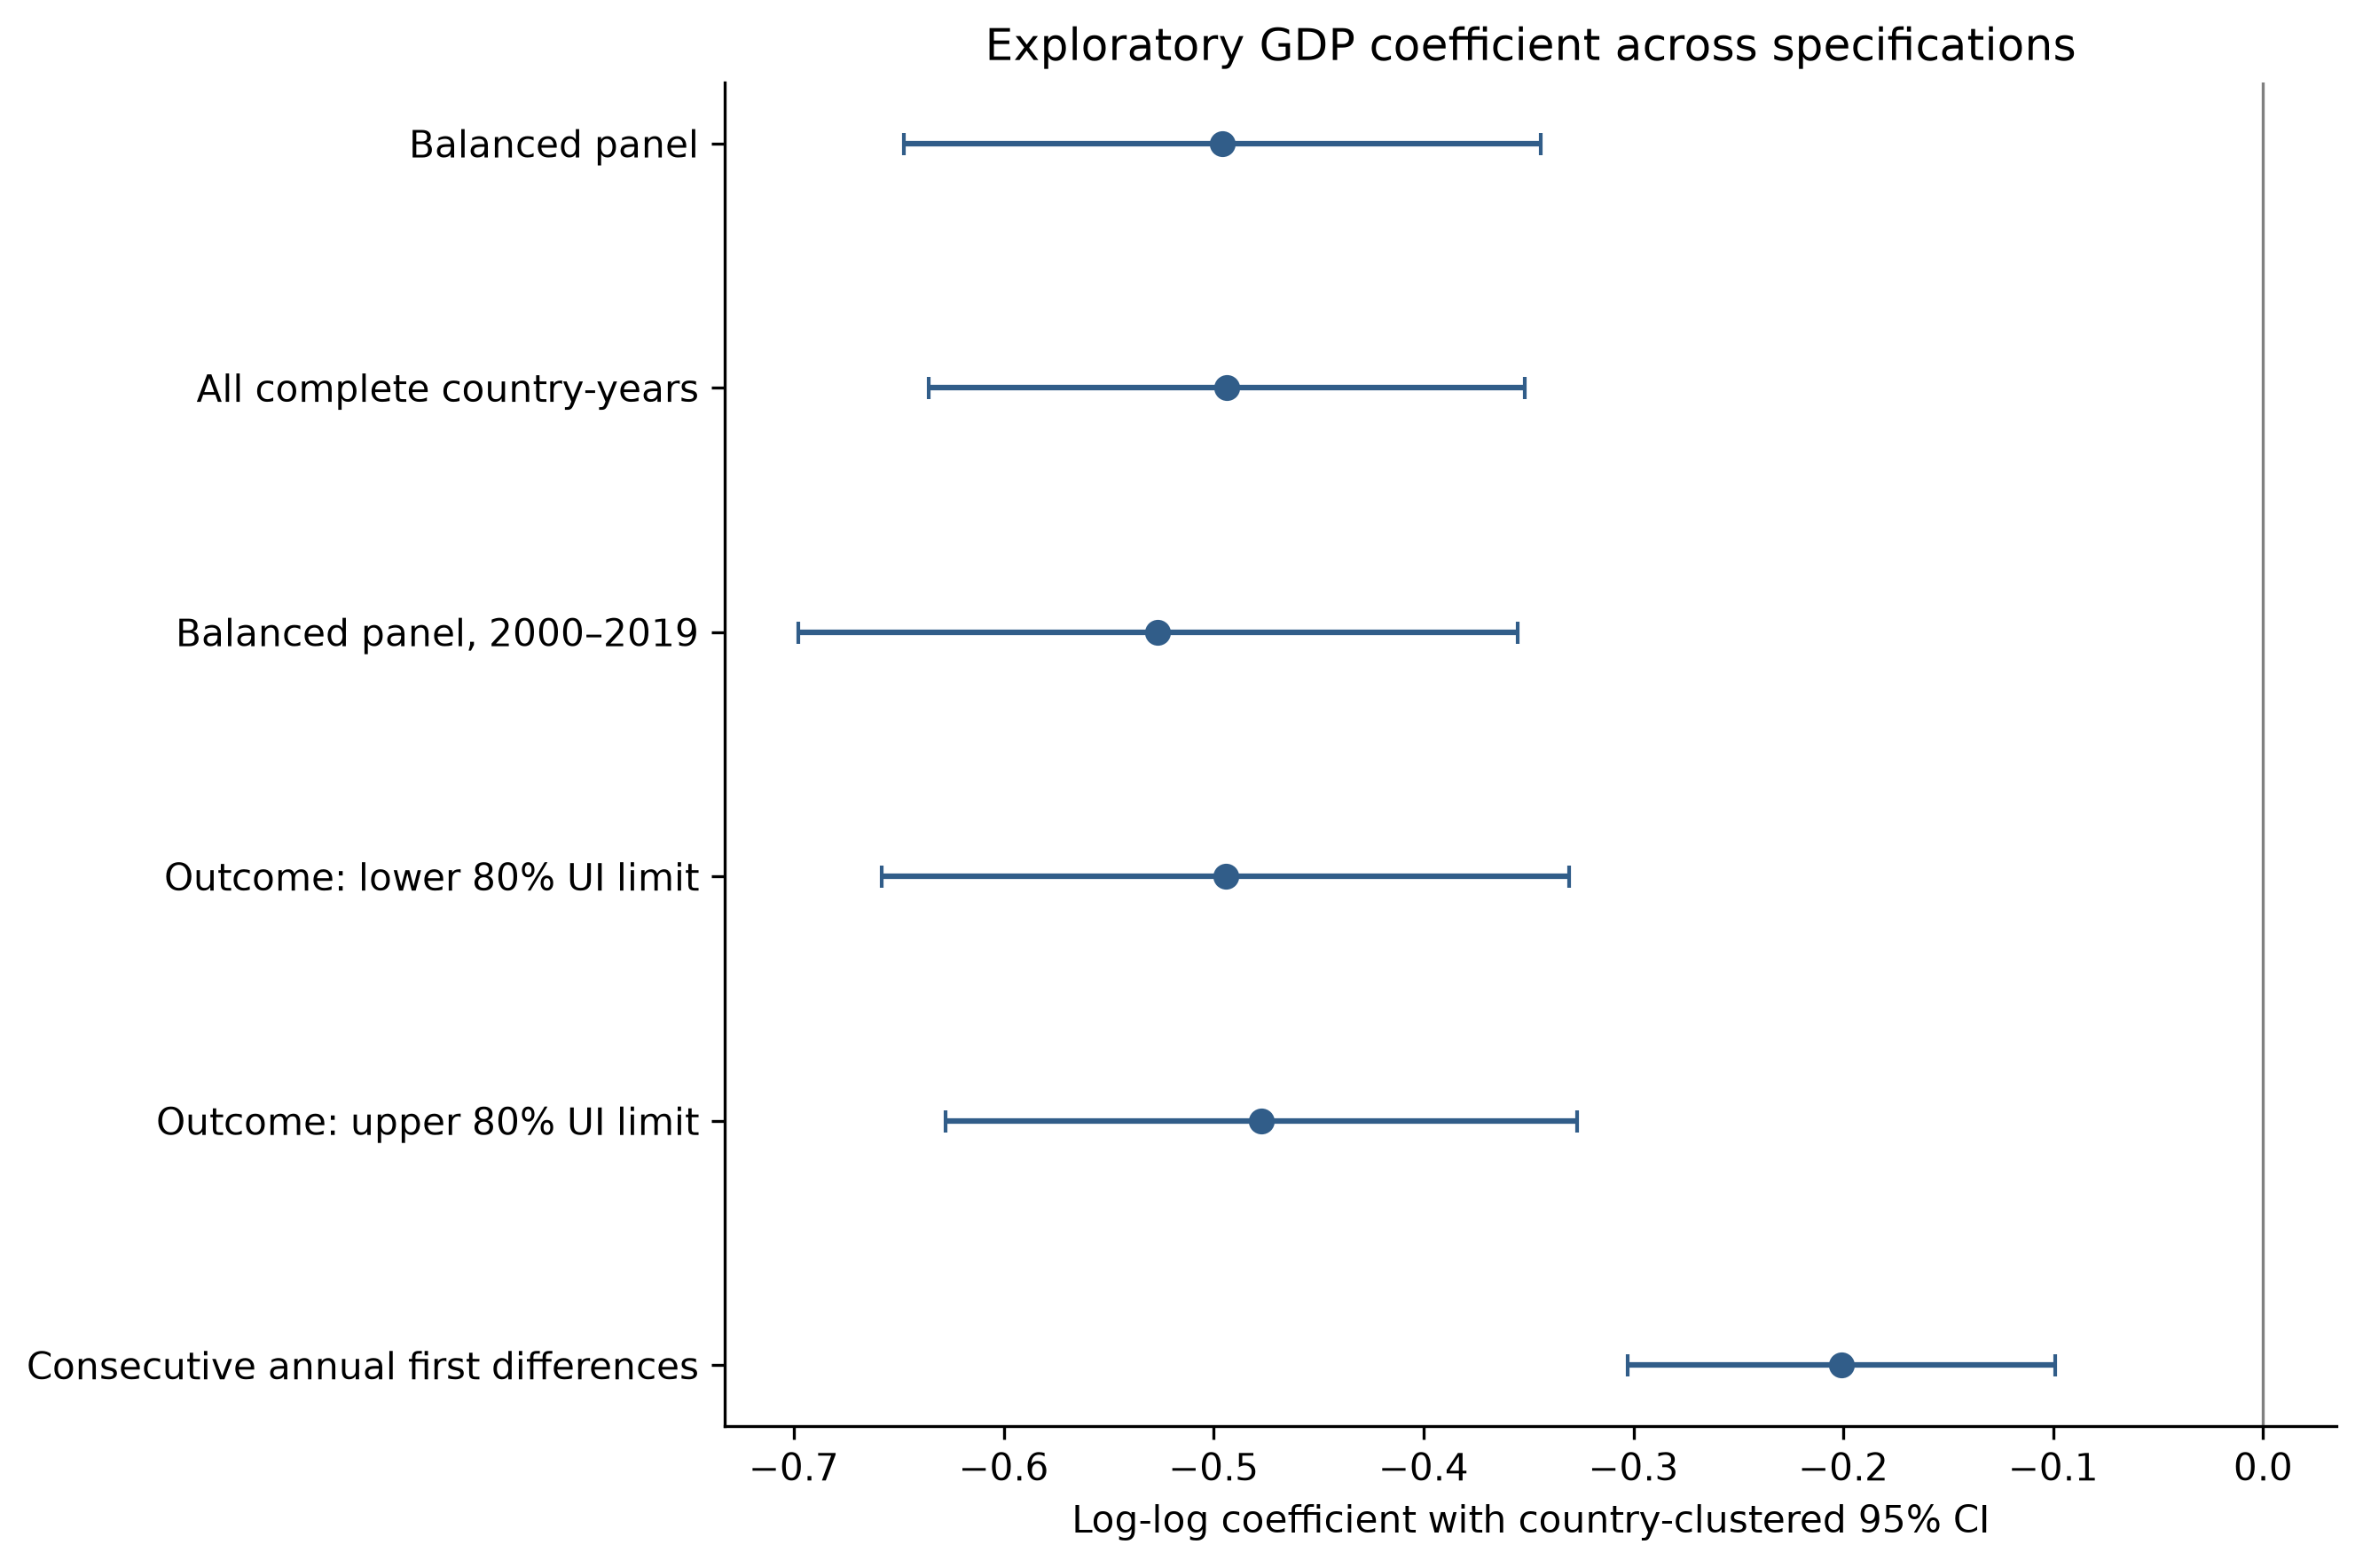

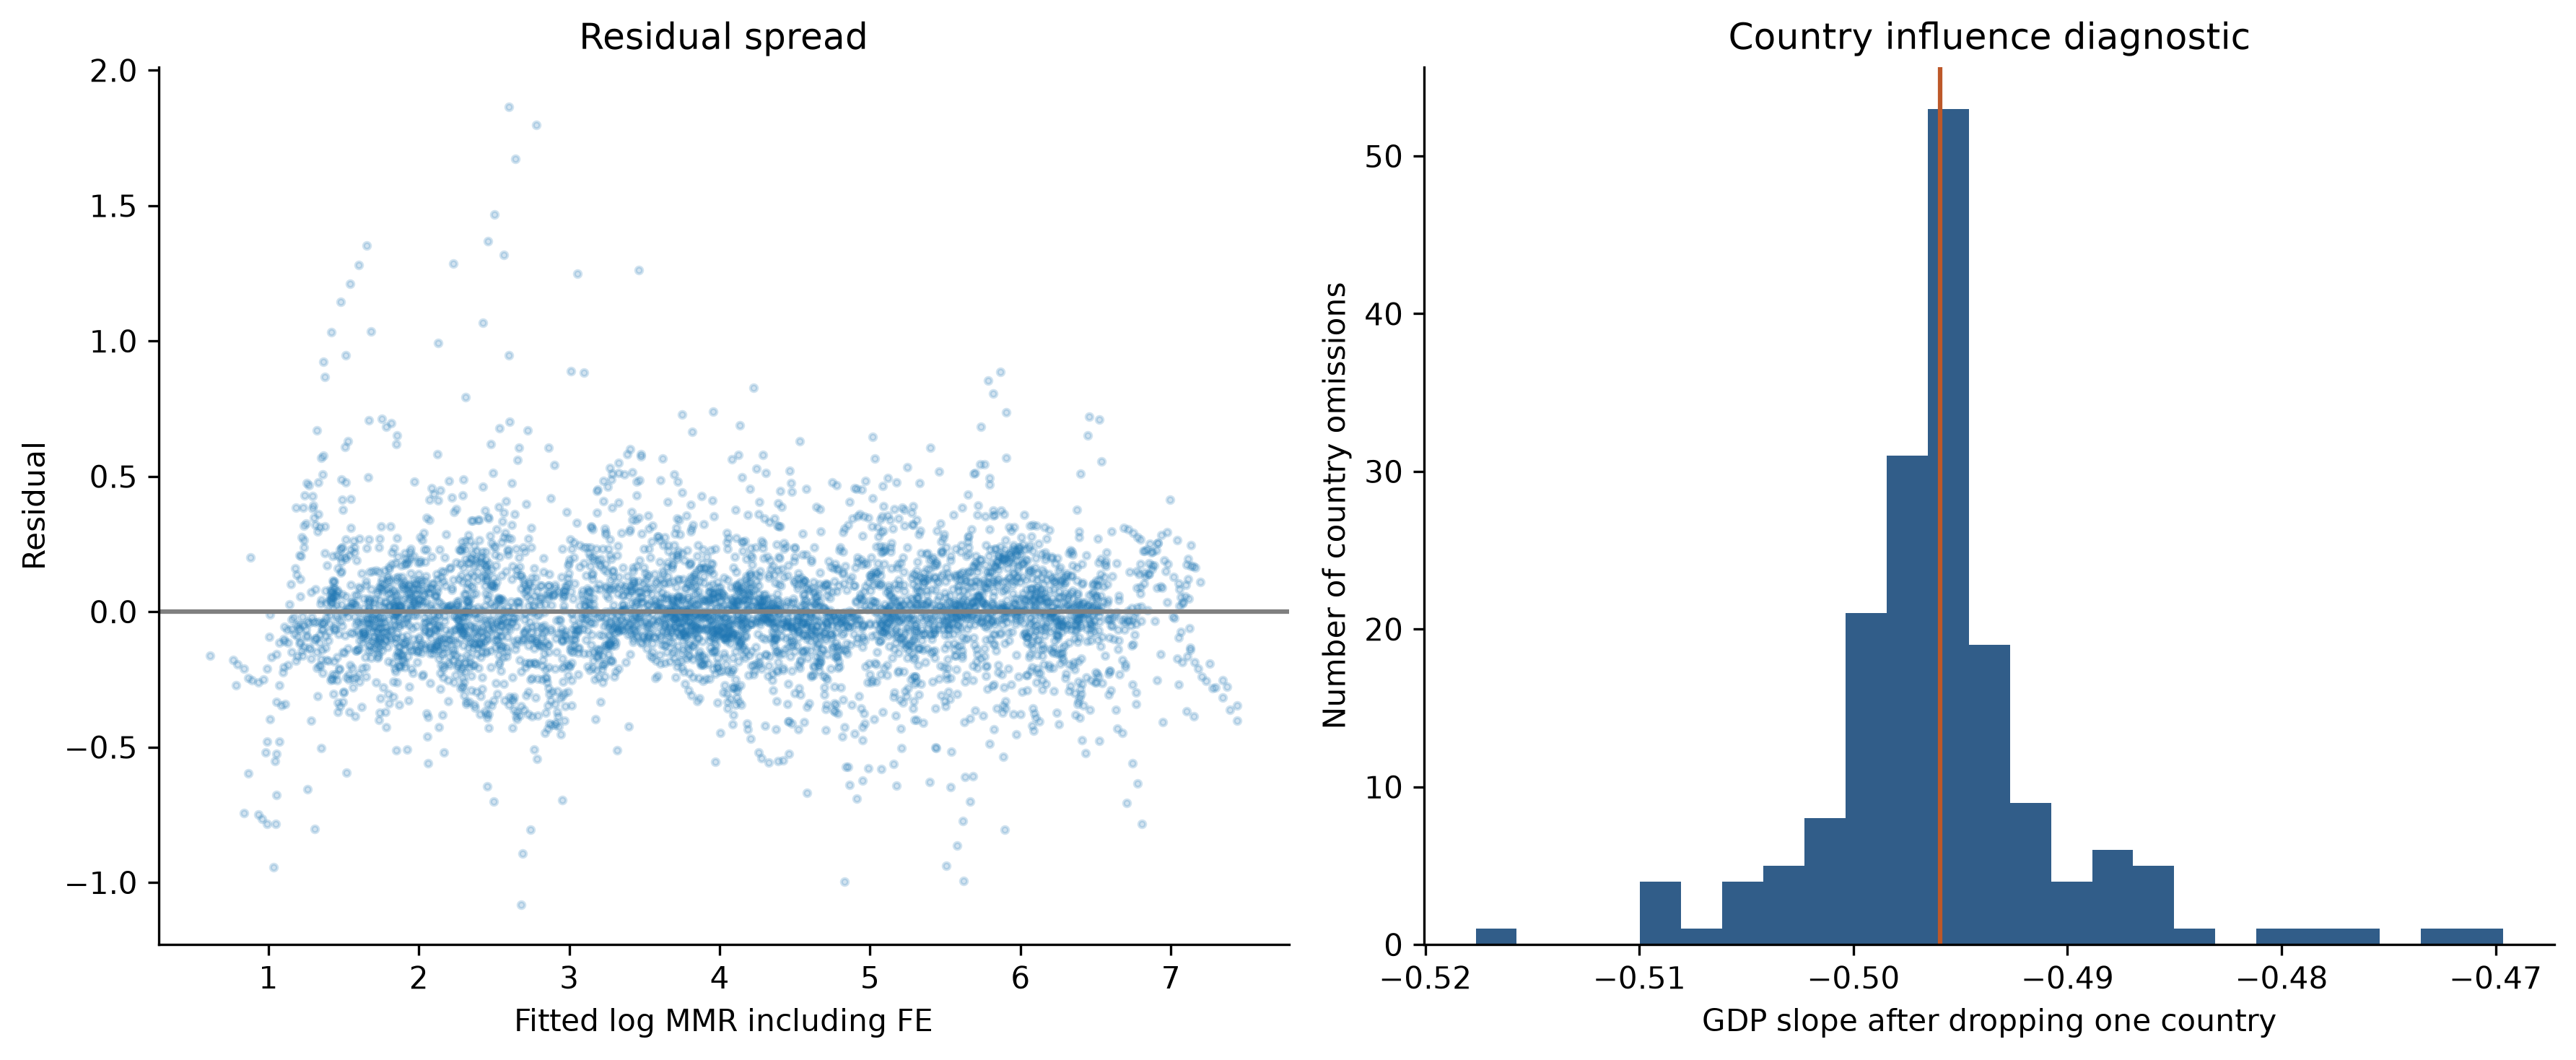

In [5]:
display(pd.DataFrame(r['vif']))
display(pd.DataFrame([r['diagnostics']]))
display(Image(filename=str(root / 'docs/images/fig5_uncertainty_forest_plot.png')))
display(Image(filename=str(root / 'docs/images/fig8_model_diagnostics.png')))

## Reproduction and interpretation

Run `python src/run_pipeline.py` from the repository root to refit the models and regenerate all outputs, then `python -m pytest -q`. Add `--integrate` to rebuild the master from cached raw files. WDI revisions can change the snapshot.

Current health expenditure does not isolate government priority. National fertility does not measure individual parity or birth spacing. Selection excludes several conflict-affected countries. A defensible CRVS-quality subset and full posterior uncertainty propagation remain open tasks.

Sources: [WHO 2025](https://www.who.int/publications/i/item/9789240108462), [WDI](https://databank.worldbank.org/source/world-development-indicators), and the repository methods/source register. AI tools assisted implementation and review.